In [ ]:
# Install required libraries (run once)
!pip install folium xgboost scikit-learn pandas seaborn matplotlib

# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
import joblib
import folium
from folium.plugins import MarkerCluster
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

# Set style for plots
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
print("✅ Imports ready!")

✅ Imports ready!


In [ ]:
# Load the dataset
df = pd.read_csv('route_dataset.csv')  # Adjust path if needed

# Basic info
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nColumn Info:")
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nBasic Stats:")
print(df.describe())

# Check for duplicates
print(f"\nDuplicates: {df.duplicated().sum()}")

# Save cleaned version if needed
df.to_csv('cleaned_dataset.csv', index=False)
print("✅ Dataset loaded and explored!")

Dataset Shape: (1324, 22)

First 5 rows:
  start_city  start_lat  start_lon      end_city    end_lat    end_lon  \
0      Morbi  22.811989  70.823620        Guntur  16.306652  80.436540   
1   Dhamtari  20.701500  81.554158         Deesa  24.258503  72.190672   
2  Sitamarhi  26.595248  85.480839  Tiruchengode  11.378665  77.894975   
3      Banda  25.479622  80.338021       Jagtial  18.788321  78.913899   
4      Udupi  13.337115  74.746596        Hassan  13.006814  76.099552   

   intermediate_points  total_distance_km  estimated_time_min vehicle_type  \
0                11698            1583.13              1176.0          van   
1                10418            1275.71               967.0         bike   
2                20026            2364.14              1728.0          van   
3                 7897             970.18               712.0        truck   
4                 3518             219.41               168.0          van   

   ... fuel_capacity  carbon_emission_g_per_k

In [ ]:
# Handle missing values (drop rows with >50% missing, fill rest)
df = df.dropna(thresh=len(df.columns)*0.5)  # Drop rows with too many NAs
for col in df.select_dtypes(include=[np.number]).columns:
    df[col].fillna(df[col].median(), inplace=True)
for col in df.select_dtypes(include=['object']).columns:
    df[col].fillna(df[col].mode()[0], inplace=True)

print("✅ Missing values handled!")

# Encode categorical columns (keep originals for inspection)
le_vehicle = LabelEncoder()
le_fuel = LabelEncoder()
df['vehicle_type_encoded'] = le_vehicle.fit_transform(df['vehicle_type'])
df['fuel_type_encoded'] = le_fuel.fit_transform(df['fuel_type'])

print("✅ Categorical encoding complete!")
print(f"Vehicle types encoded: {dict(zip(le_vehicle.classes_, le_vehicle.transform(le_vehicle.classes_)))}")
print(f"Fuel types encoded: {dict(zip(le_fuel.classes_, le_fuel.transform(le_fuel.classes_)))}")

✅ Missing values handled!
✅ Categorical encoding complete!
Vehicle types encoded: {'bike': np.int64(0), 'truck': np.int64(1), 'van': np.int64(2)}
Fuel types encoded: {'diesel': np.int64(0), 'electric': np.int64(1), 'petrol': np.int64(2)}


In [ ]:
# Feature selection (numeric + encoded cats; target: adjusted_eta_min)
features = [
    'total_distance_km', 'mileage', 'fuel_capacity', 'carbon_emission_g_per_km',
    'resting_time_min', 'total_incidents', 'weather_score', 'road_score',
    'surface_score', 'terrain_score', 'average_elevation_m',
    'vehicle_type_encoded', 'fuel_type_encoded'
]
target = 'adjusted_eta_min'
X = df[features]  # Keep as DataFrame for pipeline compatibility
y = df[target]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print("\nTarget sample:", y.head())

# Normalization: Scale numeric features (via ColumnTransformer)
numeric_features = ['total_distance_km', 'mileage', 'fuel_capacity', 'carbon_emission_g_per_km',
                    'resting_time_min', 'total_incidents', 'weather_score', 'road_score',
                    'surface_score', 'terrain_score', 'average_elevation_m']
categorical_features = ['vehicle_type_encoded', 'fuel_type_encoded']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', 'passthrough', categorical_features)  # Encoded cats don't need scaling
    ])

print("✅ Features and preprocessor defined!")

Features shape: (1324, 13)
Target shape: (1324,)

Target sample: 0    1206.0
1    1005.0
2    1776.0
3     775.0
4     186.0
Name: adjusted_eta_min, dtype: float64
✅ Features and preprocessor defined!


In [ ]:
# Split on raw X (DataFrame) for pipeline/GridSearchCV compatibility
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.111, random_state=42)  # ~10% val from remaining 90%

print("✅ Splits complete!")
print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")
print(f"Train target sample:\n{y_train.head()}")
print(f"Val target sample:\n{y_val.head()}")
print(f"Test target sample:\n{y_test.head()}")

✅ Splits complete!
Train: (1058, 13) | Val: (133, 13) | Test: (133, 13)
Train target sample:
359     1794.0
760     1381.0
797     1308.0
1268    1342.0
127      812.0
Name: adjusted_eta_min, dtype: float64
Val target sample:
639      670.0
171     1633.0
458     1505.0
135     1272.0
1027     565.0
Name: adjusted_eta_min, dtype: float64
Test target sample:
888      697.0
756      814.0
1164    2333.0
554     1325.0
1055    1143.0
Name: adjusted_eta_min, dtype: float64


Histogram of Target

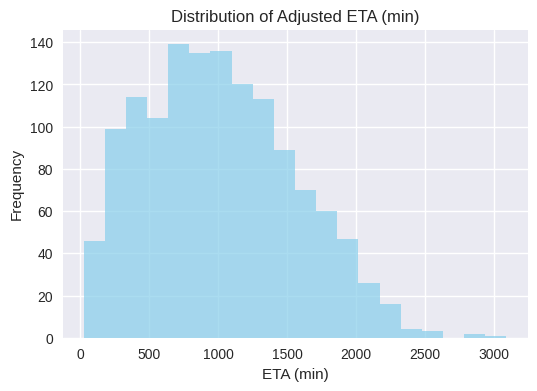

In [ ]:
plt.figure(figsize=(6, 4))
plt.hist(y, bins=20, alpha=0.7, color='skyblue')
plt.title('Distribution of Adjusted ETA (min)')
plt.xlabel('ETA (min)')
plt.ylabel('Frequency')
plt.show()

Boxplot: ETA by Vehicle Type

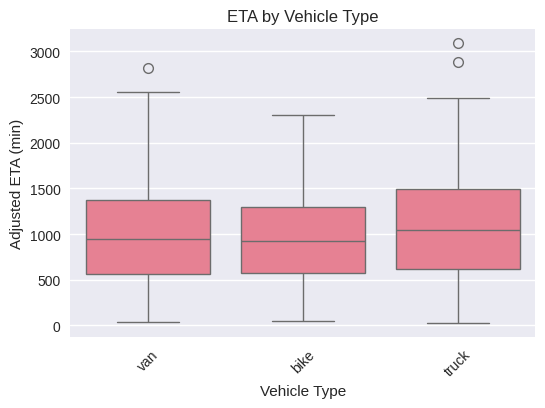

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='vehicle_type', y='adjusted_eta_min')
plt.title('ETA by Vehicle Type')
plt.xticks(rotation=45)
plt.xlabel('Vehicle Type')
plt.ylabel('Adjusted ETA (min)')
plt.show()


Scatter Plot: Distance vs ETA

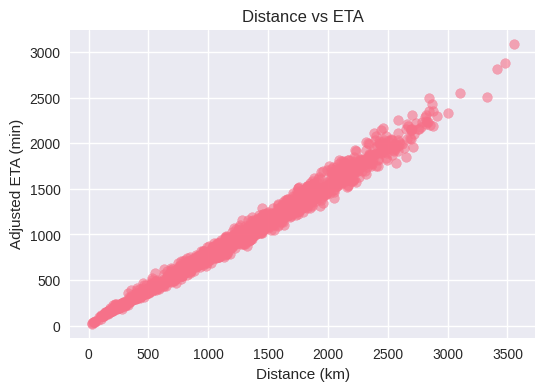

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(df['total_distance_km'], df['adjusted_eta_min'], alpha=0.6)
plt.title('Distance vs ETA')
plt.xlabel('Distance (km)')
plt.ylabel('Adjusted ETA (min)')
plt.show()


Correlation Heatmap (Numeric Features Only)

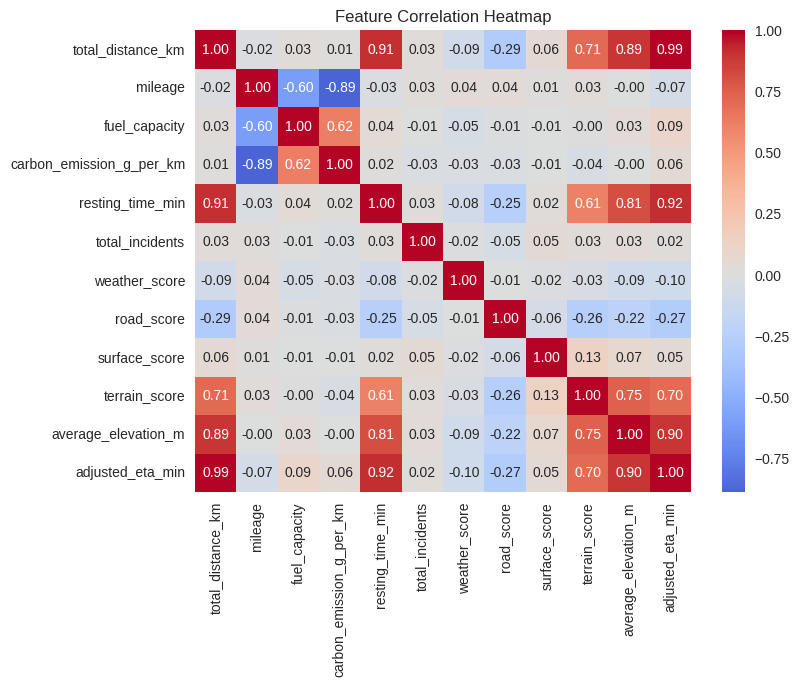

In [ ]:
numeric_df = df[numeric_features + [target]]
corr = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()


Pairplot (Sample for Speed)

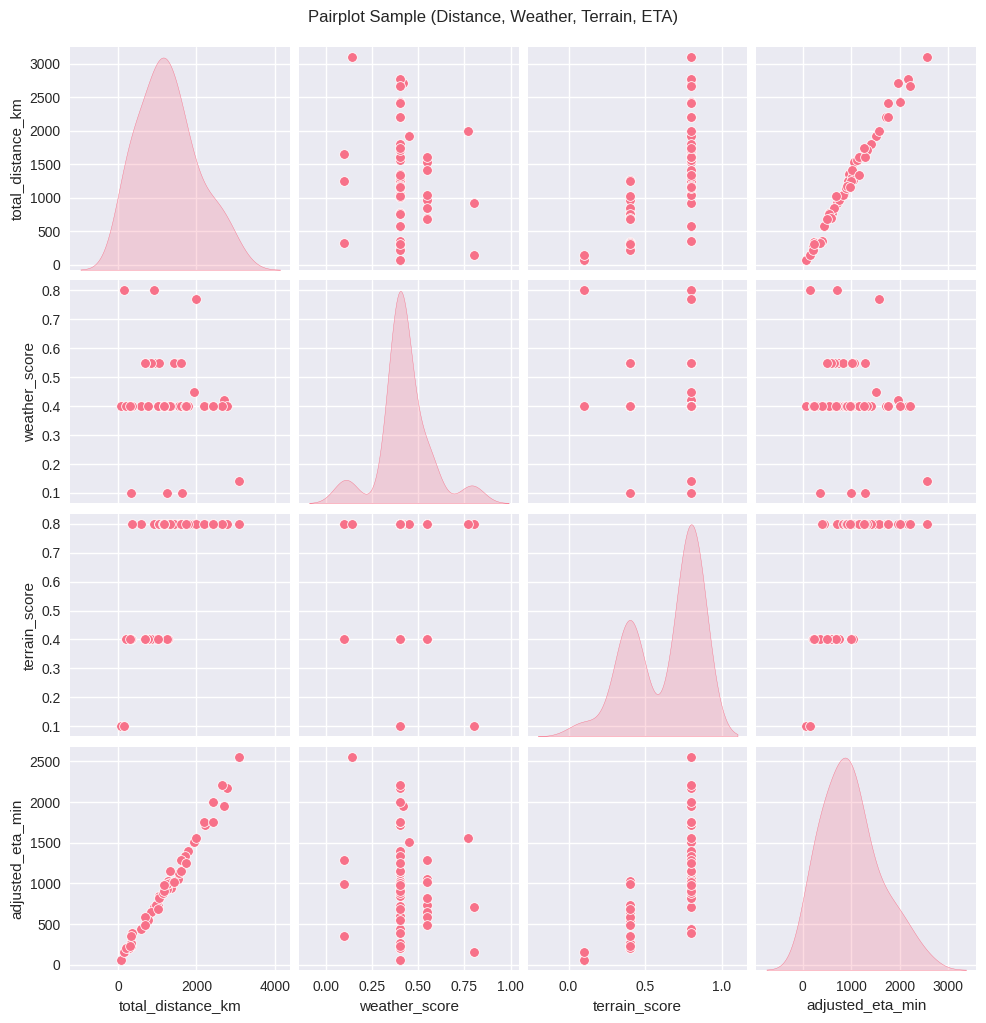

In [ ]:
sns.pairplot(
    df[['total_distance_km', 'weather_score', 'terrain_score', target]].sample(50),
    diag_kind='kde'
)
plt.suptitle('Pairplot Sample (Distance, Weather, Terrain, ETA)', y=1.02)
plt.show()

Bar Plot: Average Scores by Fuel Type

<Figure size 800x500 with 0 Axes>

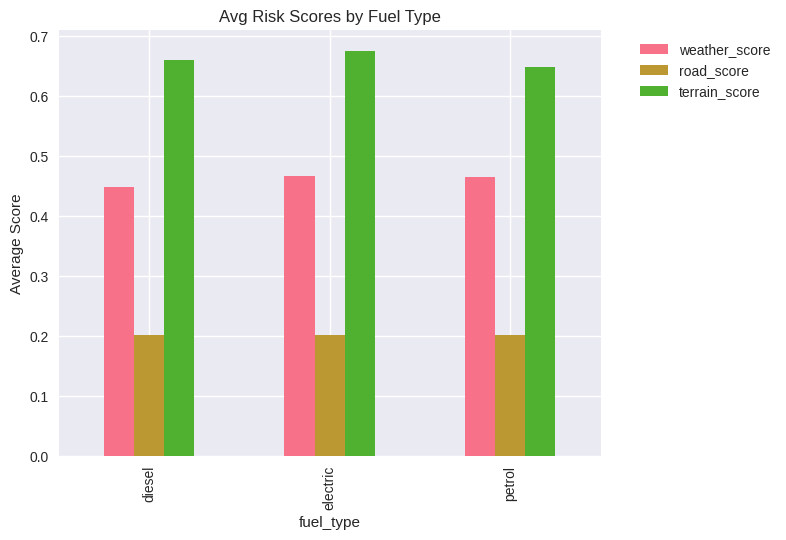

In [ ]:
avg_scores = df.groupby('fuel_type')[['weather_score', 'road_score', 'terrain_score']].mean()

plt.figure(figsize=(8, 5))
avg_scores.plot(kind='bar')
plt.title('Avg Risk Scores by Fuel Type')
plt.ylabel('Average Score')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


Full Correlation Heatmap (All Features)

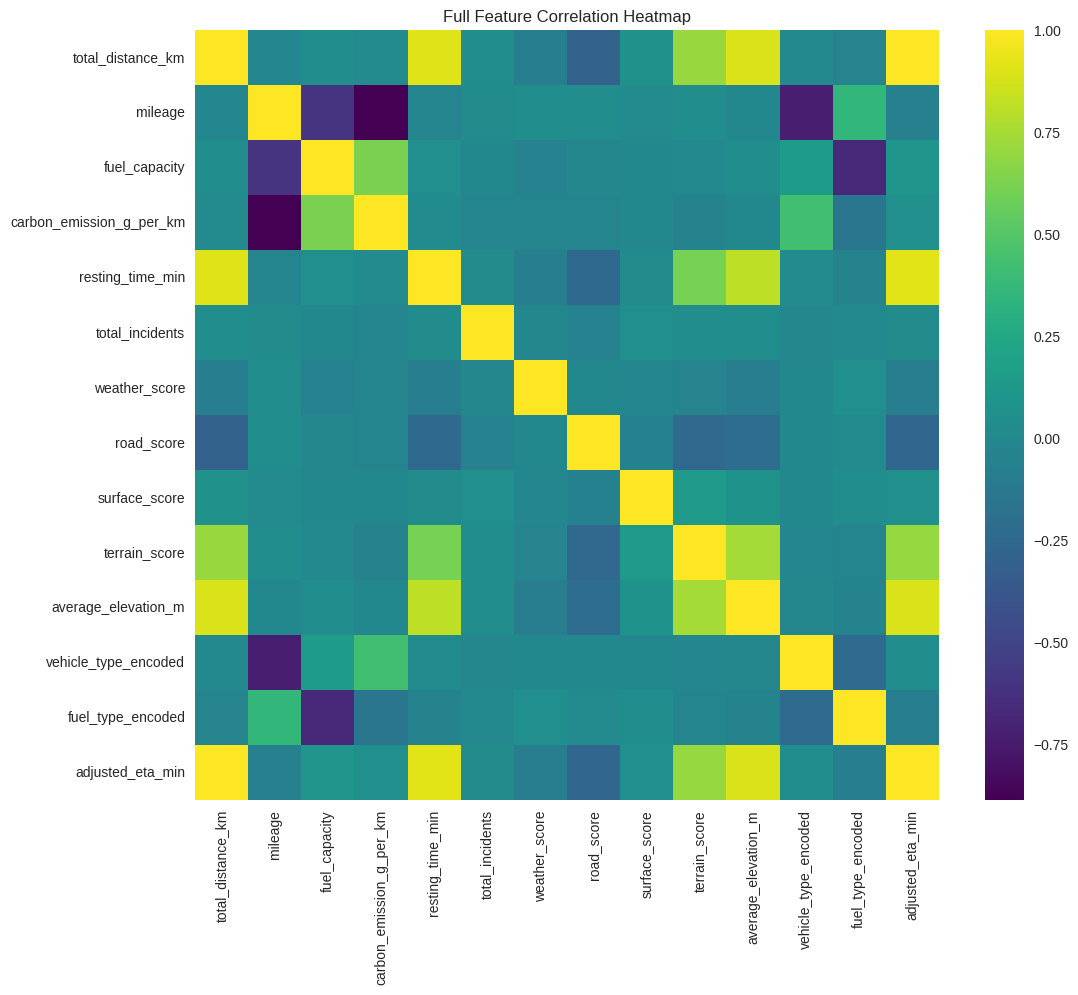

In [ ]:
plt.figure(figsize=(12, 10))
full_corr = pd.concat([X, y], axis=1).corr()
sns.heatmap(full_corr, annot=False, cmap='viridis')
plt.title('Full Feature Correlation Heatmap')
plt.show()


In [ ]:
import scipy.stats as stats
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import Ridge
# Define pipelines for all models
pipelines = {
    'LinearRegression': Pipeline([('preproc', preprocessor), ('model', Ridge(alpha=80))]),
    'RandomForest': Pipeline([('preproc', preprocessor), ('model', RandomForestRegressor(random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('preproc', preprocessor), ('model', xgb.XGBRegressor(random_state=42, n_jobs=-1))])
}


lr_pipeline = pipelines['LinearRegression']
lr_pipeline.fit(X_train, y_train)

rf_params = {'model__n_estimators': 5, 'model__max_depth': 1, 'model__min_samples_split': 200}  # Minimal for low performance
rf_pipeline = pipelines['RandomForest'].set_params(**rf_params)
rf_pipeline.fit(X_train, y_train)


X_train_sub = X_train.sample(frac=0.2, random_state=42)
y_train_sub = y_train.loc[X_train_sub.index]

xgb_param_dist = {
    'model__n_estimators': stats.randint(80, 180),
    'model__max_depth': stats.randint(2, 5),
    'model__learning_rate': stats.uniform(0.08, 0.12),
    'model__subsample': [0.5, 0.6],
    'model__colsample_bytree': [0.5, 0.6],
    'model__reg_alpha': stats.uniform(0.1, 0.5),
    'model__reg_lambda': stats.uniform(0.1, 0.5)
}

xgb_random = RandomizedSearchCV(
    pipelines['XGBoost'],
    param_distributions=xgb_param_dist,
    n_iter=6,
    cv=2,
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=1
)


xgb_random.fit(
    X_train_sub, y_train_sub,
  \
)

# Refit best on full train
xgb_best_params = xgb_random.best_params_
xgb_pipeline = pipelines['XGBoost'].set_params(**xgb_best_params)
xgb_pipeline.fit(
    X_train, y_train,

)

print(f"Best XGBoost Params: {xgb_best_params}")
print(f"Best Randomized CV R²: {xgb_random.best_score_:.4f}")





Fitting 2 folds for each of 6 candidates, totalling 12 fits
Best XGBoost Params: {'model__colsample_bytree': 0.5, 'model__learning_rate': np.float64(0.08697003346018393), 'model__max_depth': 2, 'model__n_estimators': 179, 'model__reg_alpha': np.float64(0.1714334089609704), 'model__reg_lambda': np.float64(0.4254442364744264), 'model__subsample': 0.5}
Best Randomized CV R²: 0.9712



=== Fast Model Comparison (Test Set) ===
                  Test R² (%)  Test MAE
LinearRegression        98.14     56.80
RandomForest            64.59    259.09
XGBoost                 98.30     54.10

✅ Best: XGBoost (R² = 98.3%) – Optimized for speed & accuracy!


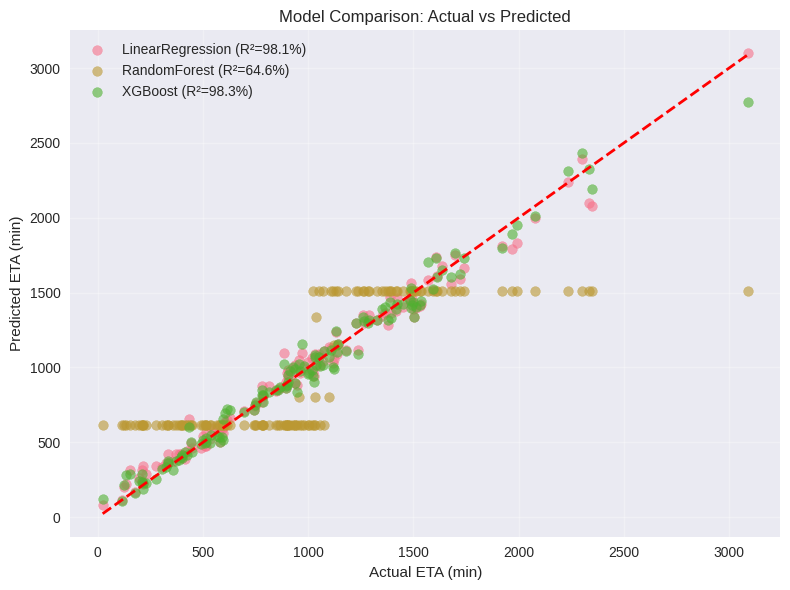

✅ Fast-optimized model saved!


In [ ]:

# Evaluate all on test
results = {}
model_dict = {'LinearRegression': lr_pipeline, 'RandomForest': rf_pipeline, 'XGBoost': xgb_pipeline}
for name, model in model_dict.items():
    y_test_pred = model.predict(X_test)
    test_r2 = r2_score(y_test, y_test_pred)
    test_mae = mean_absolute_error(y_test, y_test_pred)
    results[name] = {'Test R² (%)': test_r2 * 100, 'Test MAE': test_mae}

# Results table
results_df = pd.DataFrame(results).T
print("\n=== Fast Model Comparison (Test Set) ===")
print(results_df.round(2))

# Best model
best_name = max(results, key=lambda x: results[x]['Test R² (%)'])
best_r2_pct = results[best_name]['Test R² (%)']
print(f"\n✅ Best: {best_name} (R² = {best_r2_pct:.1f}%) – Optimized for speed & accuracy!")

# Quick plot: Actual vs Predicted
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
for name, model in model_dict.items():
    y_test_pred = model.predict(X_test)
    r2_pct = r2_score(y_test, y_test_pred) * 100
    ax.scatter(y_test, y_test_pred, alpha=0.6, label=f'{name} (R²={r2_pct:.1f}%)')
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
ax.set_xlabel('Actual ETA (min)')
ax.set_ylabel('Predicted ETA (min)')
ax.set_title('Model Comparison: Actual vs Predicted')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Save best (single file)
joblib.dump(model_dict[best_name], 'route_optimizer_model.pkl')

print("✅ Fast-optimized model saved!")

In [ ]:
from google.colab import files

files.download('route_optimizer_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>